# Klasifikator Tekstur Kayu (Wood Texture Classifier)

## Pendahuluan (Introduction)

## Persiapan Lingkungan (Environment Setup)

### Instalasi Library

In [1]:
from pathlib import Path
from urllib.request import urlopen, Request
from zipfile import ZipFile
from hashlib import md5

import shutil

In [2]:
# Direktori root/utama dari proyek
PROJECT_ROOT = Path.cwd()

In [3]:
# Menyesuaikan jika kernel notebook berjalan di tempat lain
if not (PROJECT_ROOT / ".python-version").exists():
    if (PROJECT_ROOT.parent / ".python-version").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

In [4]:
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

In [5]:
# Membuat direktori/folder "data/" beserta seisinya (jika belum ada)
DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
# Link dataset official
DATASET_URL = (
    "https://zenodo.org/records/2545611/files/"
    "Wood%20Dataset.zip?download=1"
)

ARCHIVE_PATH = DATA_DIR / "wood_dataset.zip"
EXPECTED_MD5 = "0d9932b101ac70bb3cf69e2ecaace42f"

In [7]:
# Fungsi untuk menghitung checksum MD5 dari file
def calculate_md5(file_path: Path) -> str:
    checksum = md5()

    with file_path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            checksum.update(chunk)

    return checksum.hexdigest()

In [8]:
# Menemukan direktori "train/" dan "test/"
def find_split_directory(root: Path, split_name: str):
    matches = [
        path for path in root.rglob("*")
        if path.is_dir() and path.name.lower() == split_name.lower()
    ]

    return matches[0] if len(matches) == 1 else None

In [9]:
# Mengunduh dataset (zip) jika beluma ada
if ARCHIVE_PATH.exists():
    print(f"File ditemukan: {ARCHIVE_PATH}")
else:
    print("Mengunduh Dataset 'Wood Species Dataset'...")

    request = Request(
        DATASET_URL,
        headers={"User-Agent": "WoodTextureClassifier/1.0"},
    )

    try:
        with urlopen(request, timeout=60) as response:
            with ARCHIVE_PATH.open("wb") as file:
                shutil.copyfileobj(response, file)
    except Exception:
        ARCHIVE_PATH.unlink(missing_ok=True)
        raise

    print("Download completed.")

# Verify archive integrity
actual_md5 = calculate_md5(ARCHIVE_PATH)

if actual_md5 != EXPECTED_MD5:
    ARCHIVE_PATH.unlink(missing_ok=True)
    raise ValueError(
        "Dataset checksum mismatch. The downloaded archive "
        "may be incomplete or corrupted. Please run this cell again."
    )

print("Checksum verified successfully.")

File ditemukan: /home/zkyzors/Documents/dev-stuff/projects/wood-texture-classifier/data/wood_dataset.zip
Checksum verified successfully.


In [10]:
# Melewati proses ekstraksi zip jika struktur dataset sudah ada
train_dir = find_split_directory(RAW_DIR, "Train")
test_dir = find_split_directory(RAW_DIR, "Test")

if train_dir is not None and test_dir is not None:
    print("Dataset already extracted.")
else:
    with ZipFile(ARCHIVE_PATH, "r") as archive:
        archive.extractall(RAW_DIR)

    print("Extraction completed.")

Dataset already extracted.


In [11]:
# Memvalidasi struktur folder yang telah diekstrak
train_dir = find_split_directory(RAW_DIR, "Train")
test_dir = find_split_directory(RAW_DIR, "Test")

if train_dir is None or test_dir is None:
    raise FileNotFoundError(
        "Could not uniquely identify Train/ and Test/ directories "
        "after extraction. Inspect the contents of data/raw/."
    )

print(f"Train directory: {train_dir}")
print(f"Test directory:  {test_dir}")
print(f"Raw data root:   {RAW_DIR}")

Train directory: /home/zkyzors/Documents/dev-stuff/projects/wood-texture-classifier/data/raw/Wood Dataset/Train
Test directory:  /home/zkyzors/Documents/dev-stuff/projects/wood-texture-classifier/data/raw/Wood Dataset/Test
Raw data root:   /home/zkyzors/Documents/dev-stuff/projects/wood-texture-classifier/data/raw


## Eksplorasi Dataset (Dataset Exploration)

### Proses Eksplorasi

In [12]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [13]:
from collections import Counter
import pandas as pd

In [14]:
# Fungsi untuk menampilkan daftar file gambar
def list_images(directory: Path) -> list[Path]:
    supported_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    return sorted(
        path
        for path in directory.rglob("*")
        if path.is_file()
        and path.suffix.lower() in supported_extensions
    )

In [15]:
# Daftar gambar dari direktori training
train_images = list_images(train_dir)

# Daftar gambar dari direktori testing
test_images = list_images(test_dir)

In [16]:
print(f"Total training images\t: {len(train_images)}")
print(f"Total test images\t: {len(test_images)}")

Total training images	: 5708
Total test images	: 2836


In [17]:
# Menghitung gambar di direktori training di tiap kelasnya
train_counts = Counter(
    image.parent.name for image in train_images
)

train_summary = pd.DataFrame(
    [
        {"class": label, "image_count": count}
        for label, count in sorted(
            train_counts.items(),
            key=lambda item: item[0],
        )
    ]
)

# Memvisualisasikan jumlah gambar di direktori training di tiap kelasnya
display(train_summary)

,class,image_count
0,1,936
1,10,440
2,11,552
3,12,504
4,2,200
5,3,1024
6,4,400
7,5,464
8,6,432
9,7,308


In [18]:
# Parse label dari nama file yang ada di direktori test
test_records = []

for image in test_images:
    parts = image.stem.rsplit("_", maxsplit=1)

    test_records.append({
        "filename": image.name,
        "label_from_filename": parts[1] if len(parts) == 2 else None,
        "label_parse_valid": (
            len(parts) == 2 and parts[1].isdigit()
        ),
    })

test_summary = pd.DataFrame(test_records)

# Menampilkan hasil parse label dari gambar di direktori test
print("\nTest filename parsing:")
display(test_summary.head())

# Menampilkan nama file yang tidak valid di direktori test
print("\nInvalid test filenames:")
display(
    test_summary.loc[~test_summary["label_parse_valid"]]
)


Test filename parsing:


,filename,label_from_filename,label_parse_valid
0,1000_1.jpg,1,True
1,1001_1.jpg,1,True
2,1002_1.jpg,1,True
3,1003_1.jpg,1,True
4,1004_1.jpg,1,True



Invalid test filenames:


,filename,label_from_filename,label_parse_valid


### Kesimpulan Eksplorasi

Dataset Wood Species berhasil terbaca dengan total **8.544** citra yang terbagi menjadi **5.708** citra train dan **2.836** citra test. Seluruh nama file pada `Test/` yang diperiksa juga berhasil diparsing labelnya.

Terdapat beberapa hal penting lanjut ke preprocessing dan ekstraksi fitur GLCM.

#### Ringkasan Dataset

| Kelas | Jumlah citra train | Proporsi train |
| ----- | ------------------ | -------------- |
| 1     | 936                | 16,4%          |
| 2     | 200                | 3,5%           |
| 3     | 1.024              | 17,9%          |
| 4     | 400                | 7,0%           |
| 5     | 464                | 8,1%           |
| 6     | 432                | 7,6%           |
| 7     | 308                | 5,4%           |
| 8     | 224                | 3,9%           |
| 9     | 224                | 3,9%           |
| 10    | 440                | 7,7%           |
| 11    | 552                | 9,7%           |
| 12    | 504                | 8,8%           |
| Total | 5.708              | 100%           |

Dataset memiliki 12 kelas dengan jumlah citra yang tidak seimbang. Kelas 3 memiliki citra terbanyak (1.024), sedangkan kelas 2 paling sedikit (200). Ini bukan alasan untuk langsung menghapus citra atau menyeimbangkan dataset. Kondisi ini perlu ditangani secara tepat saat evaluasi model.

#### Lanjutkan Eksplorasi Dataset

Sebelum melakukan preprocessing, kita perlu memastikan bahwa kelas pada data train dan test konsisten, mengetahui distribusi kelas pada data test, dan melihat contoh citranya.

##### Periksa Distribusi Kelas Train dan Test


In [19]:
train_counts = Counter(image.parent.name for image in train_images)
test_counts = Counter(test_summary["label_from_filename"].dropna())

all_classes = sorted(
    set(train_counts) | set(test_counts),
    key=lambda label: int(label),
)

class_distribution = pd.DataFrame([
    {
        "class": label,
        "train_count": train_counts.get(label, 0),
        "test_count": test_counts.get(label, 0),
    }
    for label in all_classes
])

class_distribution["total_count"] = (
    class_distribution["train_count"]
    + class_distribution["test_count"]
)

display(class_distribution)

print("Total train:", class_distribution["train_count"].sum())
print("Total test:", class_distribution["test_count"].sum())
print("Total keseluruhan:", class_distribution["total_count"].sum())

# Pastikan kedua split memiliki kelas yang sama
train_classes = set(train_counts)
test_classes = set(test_counts)

print("Kelas yang hanya ada di train:", sorted(
    train_classes - test_classes, key=int
))
print("Kelas yang hanya ada di test:", sorted(
    test_classes - train_classes, key=int
))


,class,train_count,test_count,total_count
0,1,936,468,1404
1,2,200,96,296
2,3,1024,508,1532
3,4,400,200,600
4,5,464,232,696
5,6,432,216,648
6,7,308,152,460
7,8,224,108,332
8,9,224,108,332
9,10,440,220,660


Total train: 5708
Total test: 2836
Total keseluruhan: 8544
Kelas yang hanya ada di train: []
Kelas yang hanya ada di test: []


Bisa dilihat dari output diatas bahwa tidak ada kelas yang yang hanya muncul di salah satu split. Ini berarti sesuai harapan.

##### Tampilkan Contoh Citra dari Setiap Kelas

In [20]:
# Install library yang dibutuhkan
%pip install matplotlib
%pip install pillow

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [21]:
from PIL import Image
import matplotlib.pyplot as plt

sample_images = []

for label in sorted(train_classes, key=int):
    class_images = sorted(
        image for image in train_images
        if image.parent.name == label
    )

    if class_images:
        sample_images.append((label, class_images[0]))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for ax, (label, image_path) in zip(axes, sample_images):
    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f"Kelas {label}")
    ax.axis("off")

for ax in axes[len(sample_images):]:
    ax.axis("off")

plt.suptitle("Contoh Citra Kayu dari Setiap Kelas")
plt.tight_layout()
plt.show()


<Figure size 1200x900 with 12 Axes>

Pada gambar-gambar diatas, ditampilkan satu sampel acak dari setiap kelasnya. Serta bisa dilihat, bahwa setiap kelas memiliki perbedaan yang signifikan. Mulai dari pola seratnya, teksturnya, garis, pori, atau variasi intensitasnya.

Meski begitu, Kelas:

* 2 dan 6
* 8, 7, dan 11

Agak sulit dibedakan jika diamati menggunakan mata telanjang.

## Pra-pemrosesan Gambar (Image Preprocessing)

Dari hasil eksplorasi, bisa diketahui bahwa dataset sudah siap untuk masuk ke tahap preprocessing. Distribusi kelas train dan testing juga sudah konsisten, serta secara visual juga sudah terlihat perbedaan tekstur antar kelas.

Di tahap ini akan dilakukan 4 hal, antara lain:

* Memeriksa apakah ada citra yang rusak atau tidak dapat dibaca
* Menkonversi citra menjadi grayscale
* Menyeragamkan semua ukuran citra agar ekstraksi fitur lebih konsisten
* Menampilkan perbandingan citra asli dan hasil preprocessing

### Menentukan Ukuran Citra

Digunakan ukuran awal sebesar $128 \times 128$ piksel. Ukuran ini merupakan kompromi untuk mengurangi beban komputasi pada device yang digunakan, sambil mempertahankan pola tekstur yang diperlukan untuk GLCM.

GLCM sendiri nantinya akan menghitung hubungan antarintensitas piksel. Untuk menjaga komputasi tetap ringan, akan digunakan jumlah level grayscale yang lebih rendah daripada 256 level penuh.

In [22]:
from PIL import Image, ImageOps
from collections import Counter

import matplotlib.pyplot as plt

In [23]:
# Ukuran gambar (128 * 128)
IMAGE_SIZE = (128, 128)

In [24]:
def preprocess_image(image_path: Path) -> Image.Image:
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image)
        image = image.convert("L")
        image = image.resize(
            IMAGE_SIZE,
            Image.Resampling.LANCZOS,
        )
        return image.copy()

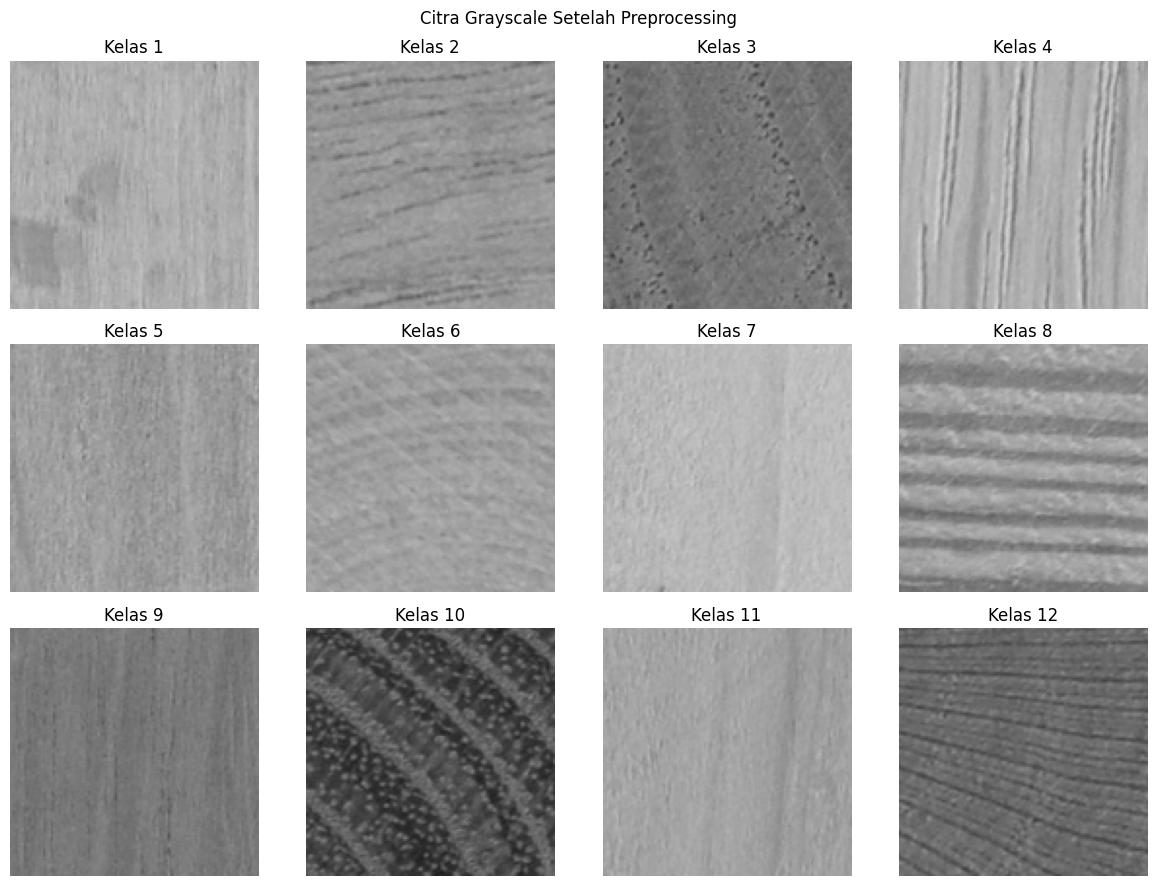

In [25]:
# Menguji preprocessing menggunakan satu citra dari setiap kelas
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for ax, (label, image_path) in zip(axes, sample_images):
    processed_image = preprocess_image(image_path)

    ax.imshow(processed_image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Kelas {label}")
    ax.axis("off")

for ax in axes[len(sample_images):]:
    ax.axis("off")

plt.suptitle("Citra Grayscale Setelah Preprocessing")
plt.tight_layout()
plt.show()


### Memeriksa Kualitas Seluruh Citra

Memastikan bahwa seluruh citra bisa dibaca adalah hal yang penting sebelum melakukan ekstraksi fitur.

In [26]:
def validate_images(image_paths: list[Path]) -> tuple[list[Path], list[dict]]:
    valid_images = []
    invalid_images = []

    for image_path in image_paths:
        try:
            with Image.open(image_path) as image:
                image.verify()
            valid_images.append(image_path)
        except Exception as error:
            invalid_images.append({
                "filename": str(image_path),
                "error": str(error),
            })

    return valid_images, invalid_images

In [27]:
valid_train_images, invalid_train_images = validate_images(train_images)
valid_test_images, invalid_test_images = validate_images(test_images)

print(f"Train valid\t: {len(valid_train_images)}")
print(f"Train invalid\t: {len(invalid_train_images)}")
print(f"Test valid\t: {len(valid_test_images)}")
print(f"Test invalid\t: {len(invalid_test_images)}")

Train valid	: 5708
Train invalid	: 0
Test valid	: 2836
Test invalid	: 0


In [28]:
if invalid_train_images:
    display(pd.DataFrame(invalid_train_images).head(10))

if invalid_test_images:
    display(pd.DataFrame(invalid_test_images).head(10))

Bisa dilihat bahwa pada cell terakhir, tidak menampilkan ouput apapun. Cell ini berisi kode yang akan menampilkan citra yang tidak valid. Dikarenakan tidak ada output, maka dapat disimpulkan bahwa tidak ada citra yang tidak valid.

Validasi ini hanya memeriksa apakah file gambar dapat dibaca atau tidak.

## Ekstraksi Fitur GLCM (GLCM Feature Extraction)

### Memahami Fitur GLCM yang Akan Digunakan

Menurut dokumentasi PyFeats, fungsi `pyfeats.glcm_features()` menghasilkan 14 fitur Haralick berupa nilai mean dan 14 fitur berupa range, sehingga totalnya 28 fitur untuk setiap citra.

Contoh fitur yang dihasilkan:

* `GLCM_ASM`
    * Keseragaman distribusi pasangan intensitas
* `GLCM_Contrast`
    * Perbedaan intensitas antarpiksel bertetangga
* `GLCM_Corrleation`
    * Hubungan statistik antarpasangan intensitas
* `GLCM_Entropy`
    * Keragaman atau ketidakaturan distribusi tekstur
* `GLCM_InverseDifferenceMoment`
    * Homogenitas lokal tekstur
* `GLCM_SumAverage`
    * Rata-rata dari distribusi jumlah intensitas

Fitur-fitur yang disediakan oleh PyFeats akan digunakan untuk melakukan perhitungan.

### Proses Ekstraksi Fitur

#### Uji Ekstraksi pada Satu Citra

In [29]:
%pip install pyfeats

INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
  Using cached opencv_python-4.14.0.94-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached opencv_python-4.13.0.92-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached opencv_python-4.13.0.90-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached opencv_python-4.12.0.88-cp37-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (19 kB)
  Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (63.0 MB)
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 5.0.0.93
    Uninstalling opencv-python-5.0.0.93:
      Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated

In [30]:
import numpy as np
import pandas as pd
import pyfeats

In [31]:
# Gunakan satu citra train sebagai sampel
sample_label, sample_path = sample_images[0]

sample_gray = preprocess_image(sample_path)
sample_array = np.asarray(sample_gray, dtype=np.uint8)

In [32]:
# Ekstraksi fitur GLCM menggunakan PyFeats
features_mean, features_range, labels_mean, labels_range = (
    pyfeats.glcm_features(
        sample_array,
        ignore_zeros=True,
    )
)

In [33]:
# Gabungkan mean dan range menjadi satu baris fitur
sample_features = {
    **dict(zip(labels_mean, features_mean)),
    **dict(zip(labels_range, features_range)),
}

sample_feature_df = pd.DataFrame([sample_features])

In [34]:
print("Kelas sampel:", sample_label)
print("Dimensi citra:", sample_array.shape)
print("Jumlah fitur mean:", len(features_mean))
print("Jumlah fitur range:", len(features_range))
print("Total fitur:", len(sample_features))

display(sample_feature_df.T.rename(columns={0: "value"}))


Kelas sampel: 1
Dimensi citra: (128, 128)
Jumlah fitur mean: 14
Jumlah fitur range: 14
Total fitur: 28


,value
GLCM_ASM_Mean,0.002452
GLCM_Contrast_Mean,37.337571
GLCM_Correlation_Mean,0.743881
GLCM_SumOfSquaresVariance_Mean,72.898880
GLCM_InverseDifferenceMoment_Mean,0.226762
GLCM_SumAverage_Mean,341.766675
GLCM_SumVariance_Mean,254.257950
GLCM_SumEntropy_Mean,5.901698
GLCM_Entropy_Mean,9.353406
GLCM_DifferenceVariance_Mean,0.000514


Hasil ini menunjukkan bahwa proses pengujian ekstraksi fitur pada satu citra telah berhasil. Maka selanjutnya akan dilakukan ekstraksi fitur untuk keseluruhan citra train dan test.

#### Ekstraksi Seluruh Citra Train dan Test

Dapat diketahui bahwa pengujian ekstraksi sebelumnya telah berhasil, maka sekarang akan dilakukan esktraksi fitur pada seluruh citra train dan test. Hasil ekstraksi nantinya akan disimpan menjadi format .csv, agar proses ekstraksi tidak perlu diulang setiap kali kernel notebook dimulai ulang.

In [35]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [36]:
from tqdm.auto import tqdm

In [37]:
FEATURE_DIR = PROCESSED_DIR
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FEATURE_PATH = FEATURE_DIR / "glcm_train.csv"
TEST_FEATURE_PATH = FEATURE_DIR / "glcm_test.csv"

In [38]:
# Fungsi untuk ekstraksi fitur GLCM
def extract_glcm_dataset(
    image_paths: list[Path],
    split: str,
) -> pd.DataFrame:
    records = []

    for image_path in tqdm(image_paths, desc=f"GLCM {split}"):
        if split == "train":
            label = image_path.parent.name
        else:
            parts = image_path.stem.rsplit("_", maxsplit=1)

            if len(parts) != 2 or not parts[1].isdigit():
                raise ValueError(
                    f"Format label tidak valid: {image_path.name}"
                )

            label = parts[1]

        image = preprocess_image(image_path)
        image_array = np.asarray(image, dtype=np.uint8)

        features_mean, features_range, labels_mean, labels_range = (
            pyfeats.glcm_features(
                image_array,
                ignore_zeros=True,
            )
        )

        feature_values = {
            **dict(zip(labels_mean, features_mean)),
            **dict(zip(labels_range, features_range)),
        }

        record = {
            "filename": image_path.name,
            "label": str(label),
            **feature_values,
        }

        records.append(record)

    return pd.DataFrame(records)

In [39]:
# Ekstraksi data train
train_features_df = extract_glcm_dataset(
    valid_train_images,
    split="train",
)

train_features_df.to_csv(TRAIN_FEATURE_PATH, index=False)

GLCM train:   0%|          | 0/5708 [00:00<?, ?it/s]

In [40]:
# Ekstraksi data test
test_features_df = extract_glcm_dataset(
    valid_test_images,
    split="test",
)

test_features_df.to_csv(TEST_FEATURE_PATH, index=False)

GLCM test:   0%|          | 0/2836 [00:00<?, ?it/s]

In [41]:
print("Ekstraksi fitur selesai.")
print("\nTrain\t\t:", train_features_df.shape)
print("Test\t\t:", test_features_df.shape)
print("CSV train\t:", TRAIN_FEATURE_PATH)
print("CSV test\t:", TEST_FEATURE_PATH)

Ekstraksi fitur selesai.

Train		: (5708, 30)
Test		: (2836, 30)
CSV train	: /home/zkyzors/Documents/dev-stuff/projects/wood-texture-classifier/data/processed/glcm_train.csv
CSV test	: /home/zkyzors/Documents/dev-stuff/projects/wood-texture-classifier/data/processed/glcm_test.csv


#### Validasi Tabel Fitur

In [42]:
# Pisahkan kolom fitur dari metadata
feature_columns = [
    column
    for column in train_features_df.columns
    if column not in {"filename", "label"}
]

In [43]:
print("Jumlah fitur\t\t:", len(feature_columns))
print("Dimensi tabel train\t:", train_features_df.shape)
print("Dimensi tabel test\t:", test_features_df.shape)

Jumlah fitur		: 28
Dimensi tabel train	: (5708, 30)
Dimensi tabel test	: (2836, 30)


In [44]:
print("\nJumlah nilai kosong:")
print("Train\t:", train_features_df[feature_columns].isna().sum().sum())
print("Test\t:", test_features_df[feature_columns].isna().sum().sum())


Jumlah nilai kosong:
Train	: 0
Test	: 0


In [45]:
print("\nJumlah nilai tak hingga:")

print(
    "Train:",
    np.isinf(train_features_df[feature_columns].to_numpy()).sum(),
)

print(
    "Test:",
    np.isinf(test_features_df[feature_columns].to_numpy()).sum(),
)

display(train_features_df.head())


Jumlah nilai tak hingga:
Train: 0
Test: 0


,filename,label,GLCM_ASM_Mean,GLCM_Contrast_Mean,GLCM_Correlation_Mean,GLCM_SumOfSquaresVariance_Mean,GLCM_InverseDifferenceMoment_Mean,GLCM_SumAverage_Mean,GLCM_SumVariance_Mean,GLCM_SumEntropy_Mean,...,GLCM_InverseDifferenceMoment_Range,GLCM_SumAverage_Range,GLCM_SumVariance_Range,GLCM_SumEntropy_Range,GLCM_Entropy_Range,GLCM_DifferenceVariance_Range,GLCM_DifferenceEntropy_Range,GLCM_Information1_Range,GLCM_Information2_Range,GLCM_MaximalCorrelationCoefficient_Range
0,100_1.jpg,1,0.002452,37.337571,0.743881,72.898880,0.226762,341.766675,254.257950,5.901698,...,0.156006,0.062131,37.931225,0.150434,0.955503,0.000437,1.049158,0.189661,0.185418,0.175875
1,101_1.jpg,1,0.001901,52.986256,0.657611,77.369924,0.201638,347.828580,256.493442,5.976416,...,0.151065,0.060039,57.635358,0.184669,1.007292,0.000399,1.159697,0.195821,0.255595,0.258534
2,102_1.jpg,1,0.002293,51.022759,0.550791,56.831673,0.199750,350.890345,176.303932,5.732460,...,0.135221,0.070805,53.119669,0.212141,0.885247,0.000367,1.063103,0.180562,0.346261,0.244958
3,103_1.jpg,1,0.002436,42.096611,0.709653,72.511608,0.212681,344.332171,247.949820,5.865035,...,0.141171,0.081324,43.928493,0.167757,0.893208,0.000389,1.033962,0.178639,0.225197,0.146957
4,104_1.jpg,1,0.002229,44.972264,0.654720,65.150051,0.205331,346.161335,215.627940,5.836872,...,0.131411,0.111036,45.591862,0.186582,0.825947,0.000347,0.966664,0.165931,0.244574,0.236204


### Ringkasan Hasil Ekstraksi

#### Ringkasan Hasil Ekstraksi

| Pemeriksaan                    | Train | Test  |
| ------------------------------ | ----- | ----- |
| Jumlah citra                   | 5.708 | 2.836 |
| Jumlah fitur GLCM per citra    | 28    | 28    |
| Jumlah kolom termasuk metadata | 30    | 30    |
| Nilai kosong pada fitur        | 0     | 0     |
| Nilai tak hingga pada fitur    | 0     | 0     |

Artinya, setiap citra telah direpresentasikan sebagai 28 nilai tekstur, ditambah dua kolom metadata:

* `filename`: Nama file  citra
* `label`: kelas spesies kayu, dari 1 sampai 12

Dengan demikian, sudah terdapat tabel untuk klasifikasi menggunakna PyCaret.

#### Apa Arti Fitur yang Dihasilkan?

Sebagai contoh, baris pertama menunjukkan nilai seperti `GLCM_ASM_Mean`, `GLCM_Contrast_Mean`, dan `GLCM_Correlation_Mean`. Nilai tersebut merangkum karakteristik tekstur citra dalam bentuk numerik.

Model nantinya akan mempelajari pola dari 28 fitur itu untuk membedakan 12 kelas kayu. Kita tidak memasukkan `filename` sebagai fitur karena nama file bukan karakteristik tekstur, dan tidak memasukkan `label` sebagai fitur karena label adalah target prediksi.

## Persiapan Fitur Dataset (Dataset Feature preparation)

Dalam tahap ini, akan dilakukan pemeriksaan duplikasi, mendeteksi kandidat outlier, dan menyiapkan data untuk PyCaret.

### Periksa Duplikasi dan Konsistensi Data

In [46]:
# Salin tabel fitur agar hasil ekstraksi asli tetap tersedia
train_df = train_features_df.copy()
test_df = test_features_df.copy()

In [47]:
# Kolom yang tidak digunakan sebagai fitur prediksi
metadata_columns = ["filename", "label"]

# Memfilter kolom yang tidak digunakan
feature_columns = [
    column for column in train_df.columns
    if column not in metadata_columns
]

# Pastikan nama fitur train dan test konsisten
assert feature_columns == [
    column for column in test_df.columns
    if column not in metadata_columns
]

In [48]:
# Pastikan seluruh fitur numerik
train_df[feature_columns] = train_df[feature_columns].apply(
    pd.to_numeric, errors="coerce"
)

test_df[feature_columns] = test_df[feature_columns].apply(
    pd.to_numeric, errors="coerce"
)

In [49]:
print("Duplikasi seluruh baris train\t:", train_df.duplicated().sum())
print("Duplikasi seluruh baris test\t:", test_df.duplicated().sum())

Duplikasi seluruh baris train	: 0
Duplikasi seluruh baris test	: 0


In [50]:
print(
    "Duplikasi kombinasi fitur train\t:",
    train_df.duplicated(subset=feature_columns).sum(),
)

print(
    "Duplikasi kombinasi fitur test\t:",
    test_df.duplicated(subset=feature_columns).sum(),
)

Duplikasi kombinasi fitur train	: 4
Duplikasi kombinasi fitur test	: 0


In [51]:
print("Nilai kosong train\t:", train_df[feature_columns].isna().sum().sum())
print("Nilai kosong test\t:", test_df[feature_columns].isna().sum().sum())

Nilai kosong train	: 0
Nilai kosong test	: 0


In [52]:
print(
    "Nilai non-finite train\t:",
    (~np.isfinite(train_df[feature_columns].to_numpy())).sum(),
)

print(
    "Nilai non-finite test\t:",
    (~np.isfinite(test_df[feature_columns].to_numpy())).sum(),
)

Nilai non-finite train	: 0
Nilai non-finite test	: 0


In [53]:
print("\nJumlah kelas train\t:", train_df["label"].nunique())
print("Jumlah kelas test\t:", test_df["label"].nunique())


Jumlah kelas train	: 12
Jumlah kelas test	: 12


### Deteksi Kandidat Outlier dengan Metode IQR

Metode Interquartile Range (IQR) menandai nilai yang berada di bawah $Q_1 - 1.5 \times IQR$ atau di atas $Q_3 + 1.5 \times IQR$.

In [54]:
Q1 = train_df[feature_columns].quantile(0.25)
Q3 = train_df[feature_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (train_df[feature_columns] < lower_bound)
    | (train_df[feature_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    "feature": feature_columns,
    "outlier_count": outlier_mask.sum().values,
    "outlier_percentage": (
        outlier_mask.mean().values * 100
    ),
}).sort_values("outlier_count", ascending=False)

display(outlier_summary)

print(
    "Baris dengan minimal satu kandidat outlier:",
    outlier_mask.any(axis=1).sum(),
    "dari",
    len(train_df),
)


,feature,outlier_count,outlier_percentage
6,GLCM_SumVariance_Mean,655,11.475123
3,GLCM_SumOfSquaresVariance_Mean,626,10.967064
17,GLCM_SumOfSquaresVariance_Range,540,9.460406
1,GLCM_Contrast_Mean,504,8.829713
20,GLCM_SumVariance_Range,404,7.077786
15,GLCM_Contrast_Range,403,7.060266
0,GLCM_ASM_Mean,328,5.746321
19,GLCM_SumAverage_Range,297,5.203224
14,GLCM_ASM_Range,269,4.712684
27,GLCM_MaximalCorrelationCoefficient_Range,241,4.222144


Baris dengan minimal satu kandidat outlier: 1762 dari 5708


IQR dihitung dari data train saja agar pemeriksaan tidak menggunakan informasi distribusi data test.

Tetapi perlu diingat bahwa nilai ekstrim pada fitur belum tentu kesalahan. Karena itu, jangan langsung menghapusnya. Jika ditemukan kandidat outlier, harus dinilai terlebih dahulu untuk menentukan valid atau tidaknya nilai tersebut.

### Interpretasi Hasil Pemeriksaan

#### Duplikasi

* Duplikasi seluruh baris: `0` pada train dan test
* Duplikasi kombinasi 28 fitur: `4` pada train dan `0` pada test

Empat baris train yang lain memiliki kombinasi fitur sama, belum tentu merupakan citra duplikat. Serta, dua citra berbeda bisa menghasilkan nilai GLCM yang sama.

#### Outlier

Sejumlah fitur memiliki kandidat outlier yang cukup banyak, terutama `GLCM_SumVariance_Mean` (655 nilai) dan `GLCM_SumOfSquaresVariance_Mean` (626 Nilai).

Angka tersebut tidak otomatis menunjukkan kesalahan data. Tekstur kayu memang dapat memiliki variasi intensitas dan pola yang besar. IQR juga menghitung batas secara global, sehingga perbedaan alami antarkelas dapat ikut ditandai sebagai outlier.

### Siapkan Data untuk PyCaret

In [55]:
# Pastikan label diperlakukan sebagai kategori klasifikasi
train_df["label"] = train_df["label"].astype(str)
test_df["label"] = test_df["label"].astype(str)

In [56]:
# Tabel untuk PyCaret: fitur + target, tanpa filename
train_model_df = train_df[feature_columns + ["label"]].copy()
test_model_df = test_df[feature_columns + ["label"]].copy()


In [57]:
print("Train untuk pemodelan\t\t:", train_model_df.shape)
print("Test untuk evaluasi akhir\t:", test_model_df.shape)

Train untuk pemodelan		: (5708, 29)
Test untuk evaluasi akhir	: (2836, 29)


In [58]:
print("\nDistribusi label train:")
display(train_model_df["label"].value_counts().sort_index())


Distribusi label train:


label
1      936
10     440
11     552
12     504
2      200
3     1024
4      400
5      464
6      432
7      308
8      224
9      224
Name: count, dtype: int64

In [59]:
print("\nDistribusi label test:")
display(test_model_df["label"].value_counts().sort_index())


Distribusi label test:


label
1     468
10    220
11    276
12    252
2      96
3     508
4     200
5     232
6     216
7     152
8     108
9     108
Name: count, dtype: int64

## Perbandingan Model (Model Comparison)

### Inisialisasi PyCaret

In [60]:
# Install pycaret
%pip install pycaret

Note: you may need to restart the kernel to use updated packages.


In [61]:
from pycaret.classification import (
    setup,
    compare_models,
    tune_model,
    pull,
    create_model,
    finalize_model,
    predict_model,
    plot_model,
)

In [62]:
# Pastikan fitur dan target tidak mengandung nilai tidak valid
assert train_model_df[feature_columns].notna().all().all()
assert test_model_df[feature_columns].notna().all().all()

assert np.isfinite(
    train_model_df[feature_columns].to_numpy(dtype=float)
).all()

assert np.isfinite(
    test_model_df[feature_columns].to_numpy(dtype=float)
).all()

In [63]:
# Inisialisasi eksperimen klasifikasi
clf = setup(
    data=train_model_df,
    target="label",
    session_id=42,
    train_size=0.8,
    data_split_stratify=True,
    normalize=True,
    normalize_method="zscore",
    fix_imbalance=False,
    remove_outliers=False,
    fold=5,
    n_jobs=2,
    html=False,
    verbose=True,
)


                    Description  \
0                    Session id   
1                        Target   
2                   Target type   
3                Target mapping   
4           Original data shape   
5        Transformed data shape   
6   Transformed train set shape   
7    Transformed test set shape   
8              Numeric features   
9                    Preprocess   
10              Imputation type   
11           Numeric imputation   
12       Categorical imputation   
13                    Normalize   
14             Normalize method   
15               Fold Generator   
16                  Fold Number   
17                     CPU Jobs   
18                      Use GPU   
19               Log Experiment   
20              Experiment Name   
21                          USI   

                                                Value  
0                                                  42  
1                                               label  
2                         

Beberapa alasan untuk konfigurasi ini:

* `data_split_stratify=True`
    * Mempertahankan proporsi kelas pada pembagian internal train dan holdout.
* `normalize=True`
    * Menstandarkan fitur, berguna khususnya untuk algoritma yang sensitif terhadap skala.
* `fix_imbalance=False`
    * Kita tidak melakukan oversampling secara otomatis; distribusi kelas akan dievaluasi melalui metrik yang sesuai.
* `remove_outliers=False`
    * Kita tidak membuang kandidat outlier yang belum terbukti sebagai kesalahan.
* `n_jobs=2`
    * Membatasi paralelisme agar lebih ramah pada laptop.

PyCaret menggunakan bagian data train untuk validasi silang dan menyisihkan sebagian sebagai holdout internal. Data test resmi tidak dimasukkan ke `setup()`.

### Bandingkan Model

Setelah `setup()` berhasil, dilakukan perbandingan model.

In [64]:
best_models = compare_models(
    sort="F1",
    n_select=5,
    include=[
        "lr",
        "knn",
        "dt",
        "rf",
        "et",
        "nb",
        "qda",
        "lda",
        "ridge",
    ],
)

comparison_results = pull()
display(comparison_results)

                                 Model  Accuracy     AUC  Recall   Prec.  \
et              Extra Trees Classifier    0.7876  0.9780  0.7876  0.7908   
rf            Random Forest Classifier    0.7665  0.9747  0.7665  0.7704   
qda    Quadratic Discriminant Analysis    0.7302  0.0000  0.7302  0.7612   
knn             K Neighbors Classifier    0.7203  0.9414  0.7203  0.7255   
lr                 Logistic Regression    0.6708  0.0000  0.6708  0.6677   
dt            Decision Tree Classifier    0.6445  0.8018  0.6445  0.6462   
lda       Linear Discriminant Analysis    0.6351  0.0000  0.6351  0.6405   
ridge                 Ridge Classifier    0.5979  0.0000  0.5979  0.5858   
nb                         Naive Bayes    0.3820  0.8249  0.3820  0.4510   

           F1   Kappa     MCC  TT (Sec)  
et     0.7852  0.7611  0.7618     0.534  
rf     0.7632  0.7373  0.7381     1.090  
qda    0.7335  0.6996  0.7024     0.090  
knn    0.7166  0.6850  0.6867     0.266  
lr     0.6604  0.6284  0.6299

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
et,Extra Trees Classifier,0.7876,0.9780,0.7876,0.7908,0.7852,0.7611,0.7618,0.534
rf,Random Forest Classifier,0.7665,0.9747,0.7665,0.7704,0.7632,0.7373,0.7381,1.090
qda,Quadratic Discriminant Analysis,0.7302,0.0000,0.7302,0.7612,0.7335,0.6996,0.7024,0.090
knn,K Neighbors Classifier,0.7203,0.9414,0.7203,0.7255,0.7166,0.6850,0.6867,0.266
lr,Logistic Regression,0.6708,0.0000,0.6708,0.6677,0.6604,0.6284,0.6299,1.860
dt,Decision Tree Classifier,0.6445,0.8018,0.6445,0.6462,0.6441,0.6023,0.6026,0.254
lda,Linear Discriminant Analysis,0.6351,0.0000,0.6351,0.6405,0.6298,0.5893,0.5909,0.086
ridge,Ridge Classifier,0.5979,0.0000,0.5979,0.5858,0.5609,0.5401,0.5476,0.070
nb,Naive Bayes,0.3820,0.8249,0.3820,0.4510,0.3684,0.3209,0.3292,0.074


Digunakan F1 sebagai kriteria pengurutan awal karena distribusi kelas tidak seimbang. Untuk klasifikasi multikelas, periksa juga metrik Accuracy, Recall, dan Prec. pada tabel hasil. Daftar algoritma sengaja dibatasi agar eksperimen awal tidak terlalu berat.

## Hyperparameter Tuning

### Kesimpulan dari Perbandingan Model

Dari hasil `compare_models()`, dua model yang paling layak untuk di tuning adalah Extra Trees Classifier dan Random Forest Classifier. Keduanya merupakan model berbasis ensemble pohon keputusan, dan keduanya sama-sama mengungguli model lain pada metrik F1 di atas.

Extra Trees unggul atas Random Forest sebesar 2,11 poin persentase pada accuracy dan 0,0220 pada F1. Waktu pelatihan yang tercatat juga lebih singkat pada eksperimen awal, yakni 0,534 detik dibandingkan 1,090 detik.

### Tuning Extra Trees dan Random Forest

#### Hyperparameter Tuning untuk Extra Trees

In [68]:
et_model = create_model("et")

tuned_et = tune_model(
    et_model,
    optimize="F1",
    n_iter=10,
    choose_better=True,
)

et_tuning_results = pull()

print("Hasil tuning Extra Trees:")
display(et_tuning_results)


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7768  0.9764  0.7768  0.7788  0.7744  0.7491  0.7499
1       0.8018  0.9827  0.8018  0.8025  0.7984  0.7769  0.7774
2       0.7809  0.9741  0.7809  0.7847  0.7775  0.7533  0.7542
3       0.7842  0.9767  0.7842  0.7902  0.7836  0.7576  0.7580
4       0.7941  0.9799  0.7941  0.7980  0.7921  0.7687  0.7693
Mean    0.7876  0.9780  0.7876  0.7908  0.7852  0.7611  0.7618
Std     0.0091  0.0030  0.0091  0.0086  0.0089  0.0102  0.0101


Fitting 5 folds for each of 10 candidates, totalling 50 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.6477  0.9401  0.6477  0.6787  0.6315  0.5999  0.6034
1       0.6539  0.9502  0.6539  0.6916  0.6359  0.6054  0.6103
2       0.6484  0.9400  0.6484  0.6280  0.6257  0.6003  0.6038
3       0.5991  0.9358  0.5991  0.5943  0.5818  0.5452  0.5481
4       0.6353  0.9442  0.6353  0.6749  0.6183  0.5861  0.5895
Mean    0.6369  0.9421  0.6369  0.6535  0.6187  0.5874  0.5910
Std     0.0198  0.0049  0.0198  0.0366  0.0193  0.0220  0.0225
Hasil tuning Extra Trees:


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6477,0.9401,0.6477,0.6787,0.6315,0.5999,0.6034
1,0.6539,0.9502,0.6539,0.6916,0.6359,0.6054,0.6103
2,0.6484,0.9400,0.6484,0.6280,0.6257,0.6003,0.6038
3,0.5991,0.9358,0.5991,0.5943,0.5818,0.5452,0.5481
4,0.6353,0.9442,0.6353,0.6749,0.6183,0.5861,0.5895
Mean,0.6369,0.9421,0.6369,0.6535,0.6187,0.5874,0.5910
Std,0.0198,0.0049,0.0198,0.0366,0.0193,0.0220,0.0225


#### Hyperparameter untuk Random Forest

In [69]:
rf_model = create_model("rf")

tuned_rf = tune_model(
    rf_model,
    optimize="F1",
    n_iter=10,
    choose_better=True,
)

rf_tuning_results = pull()

print("Hasil tuning Random Forest:")
display(rf_tuning_results)


      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7735  0.9739  0.7735  0.7777  0.7709  0.7455  0.7463
1       0.7788  0.9798  0.7788  0.7793  0.7749  0.7508  0.7515
2       0.7678  0.9701  0.7678  0.7715  0.7642  0.7386  0.7393
3       0.7470  0.9737  0.7470  0.7520  0.7454  0.7156  0.7161
4       0.7656  0.9760  0.7656  0.7717  0.7609  0.7363  0.7372
Mean    0.7665  0.9747  0.7665  0.7704  0.7632  0.7373  0.7381
Std     0.0108  0.0032  0.0108  0.0097  0.0102  0.0120  0.0121


Fitting 5 folds for each of 10 candidates, totalling 50 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).
      Accuracy     AUC  Recall   Prec.      F1   Kappa     MCC
Fold                                                          
0       0.7046  0.9618  0.7046  0.7168  0.6974  0.6667  0.6681
1       0.7218  0.9684  0.7218  0.7307  0.7117  0.6853  0.6870
2       0.7054  0.9605  0.7054  0.7119  0.6940  0.6669  0.6688
3       0.6933  0.9598  0.6933  0.7032  0.6885  0.6543  0.6554
4       0.7141  0.9641  0.7141  0.7245  0.7061  0.6778  0.6792
Mean    0.7078  0.9629  0.7078  0.7174  0.6995  0.6702  0.6717
Std     0.0096  0.0031  0.0096  0.0096  0.0083  0.0106  0.0107
Hasil tuning Random Forest:


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7046,0.9618,0.7046,0.7168,0.6974,0.6667,0.6681
1,0.7218,0.9684,0.7218,0.7307,0.7117,0.6853,0.6870
2,0.7054,0.9605,0.7054,0.7119,0.6940,0.6669,0.6688
3,0.6933,0.9598,0.6933,0.7032,0.6885,0.6543,0.6554
4,0.7141,0.9641,0.7141,0.7245,0.7061,0.6778,0.6792
Mean,0.7078,0.9629,0.7078,0.7174,0.6995,0.6702,0.6717
Std,0.0096,0.0031,0.0096,0.0096,0.0083,0.0106,0.0107


## Evaluasi Model (Model Evaluation)

## Kesimpulan